In [1]:
import numpy as np
from numpy import pi
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_aer import AerSimulator


In [2]:
def qft_rotations(circuit, n):
    if n == 0:
        return circuit

    n -= 1
    circuit.h(n)
    for qubit in range(n):
        circuit.cp(pi / 2 ** (n - qubit), qubit, n)

    qft_rotations(circuit, n)

In [3]:
n = 7

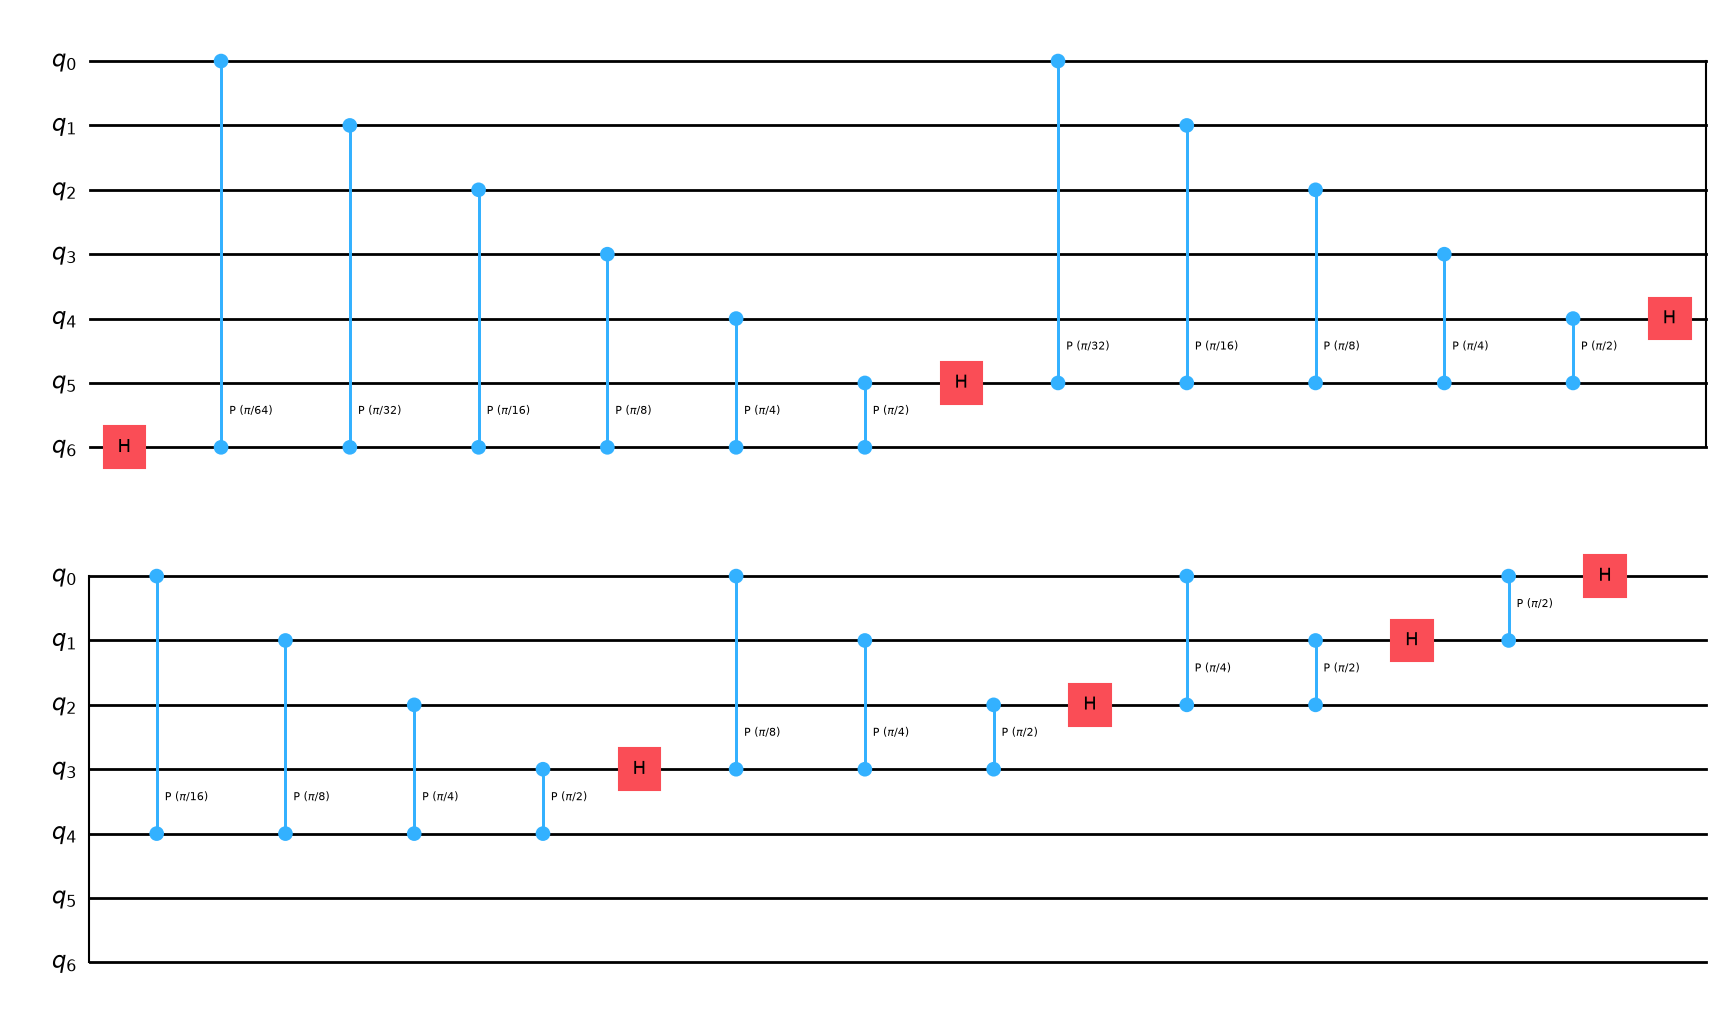

In [4]:
qc = QuantumCircuit(n)
qft_rotations(qc, n)
qc.draw(output='mpl')

In [5]:
def swap_registers(circuit, n):
    for qubit in range(n // 2):
        circuit.swap(qubit, n - qubit - 1)
    return circuit

In [6]:
def qft(circuit, n):
    qft_rotations(circuit, n)
    swap_registers(circuit, n)
    return circuit

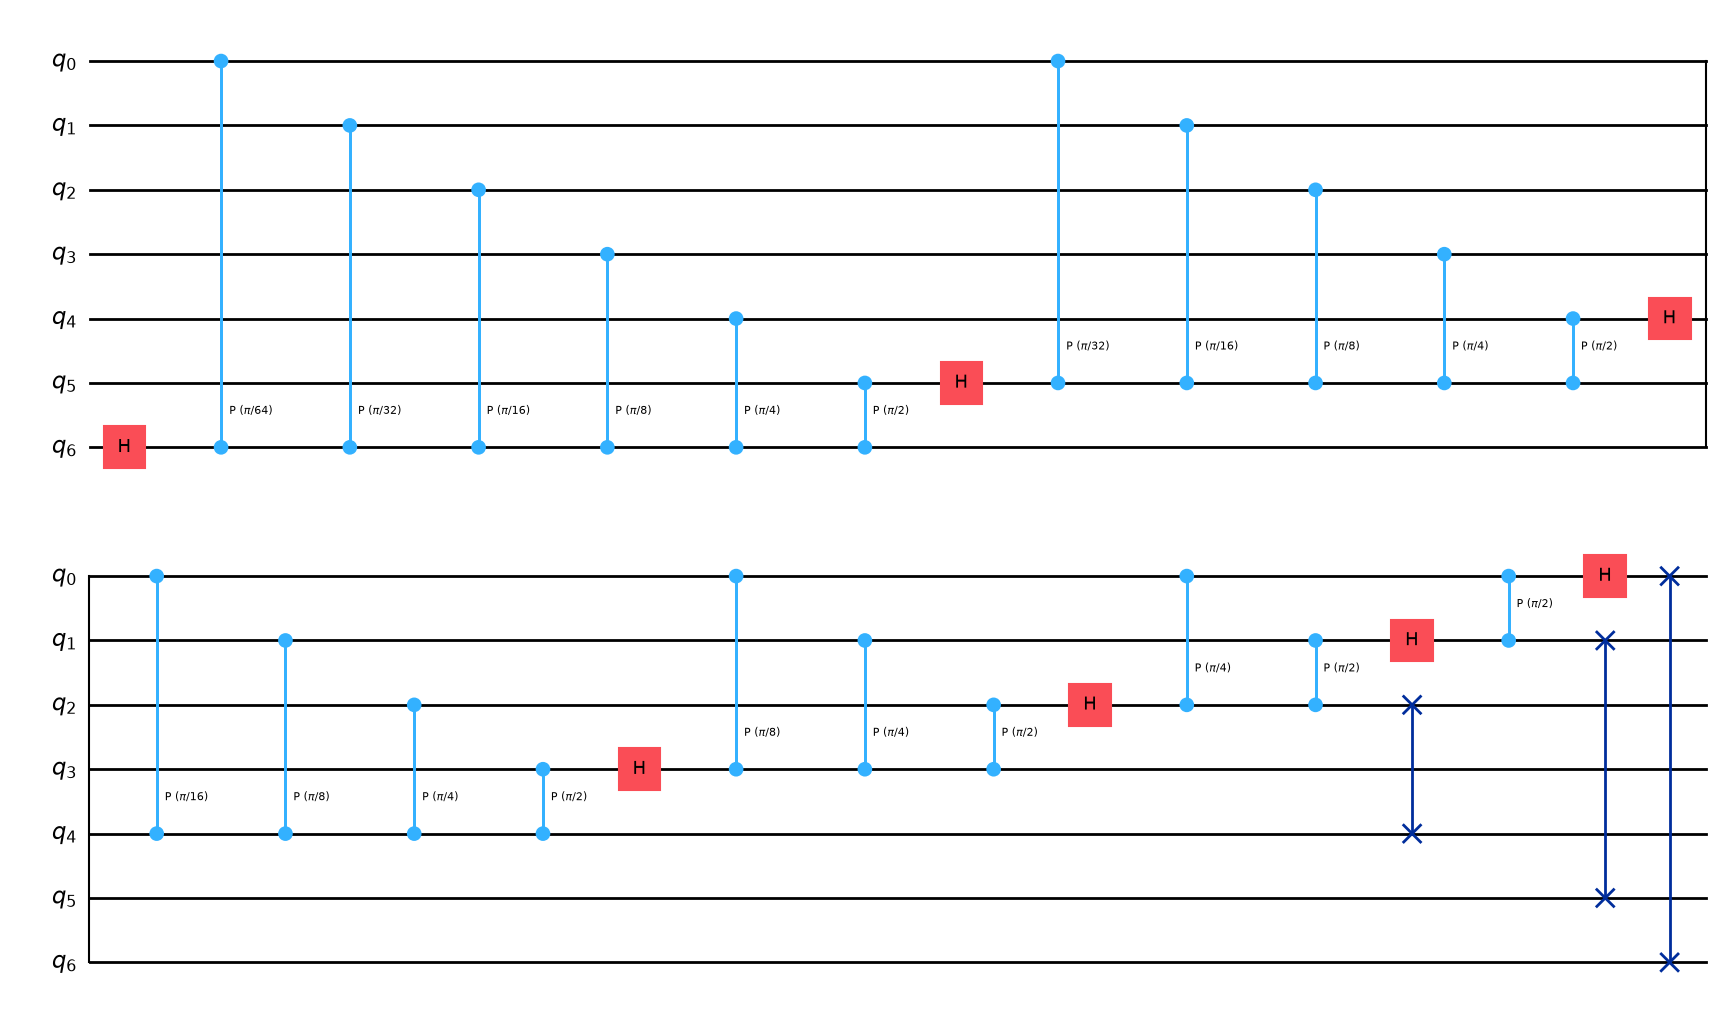

In [7]:
qc = QuantumCircuit(n)
qft(qc, n)
qc.draw(output='mpl')

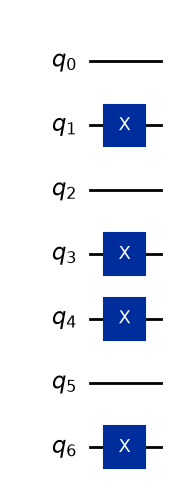

In [8]:
bits = [0, 1, 0, 1, 1, 0, 1]
qc = QuantumCircuit(n)
for i, bit in enumerate(bits):
    if bit:
        qc.x(i)
qc.draw(output='mpl')

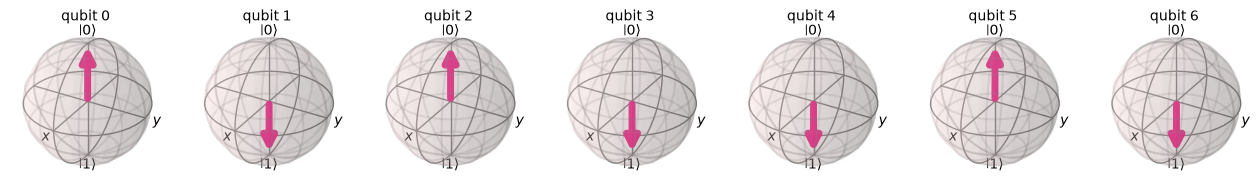

In [9]:
sim = AerSimulator()
qc_init = qc.copy()
qc_init.save_statevector()
state_vector = sim.run(transpile(qc_init, sim)).result().get_statevector()
plot_bloch_multivector(state_vector)

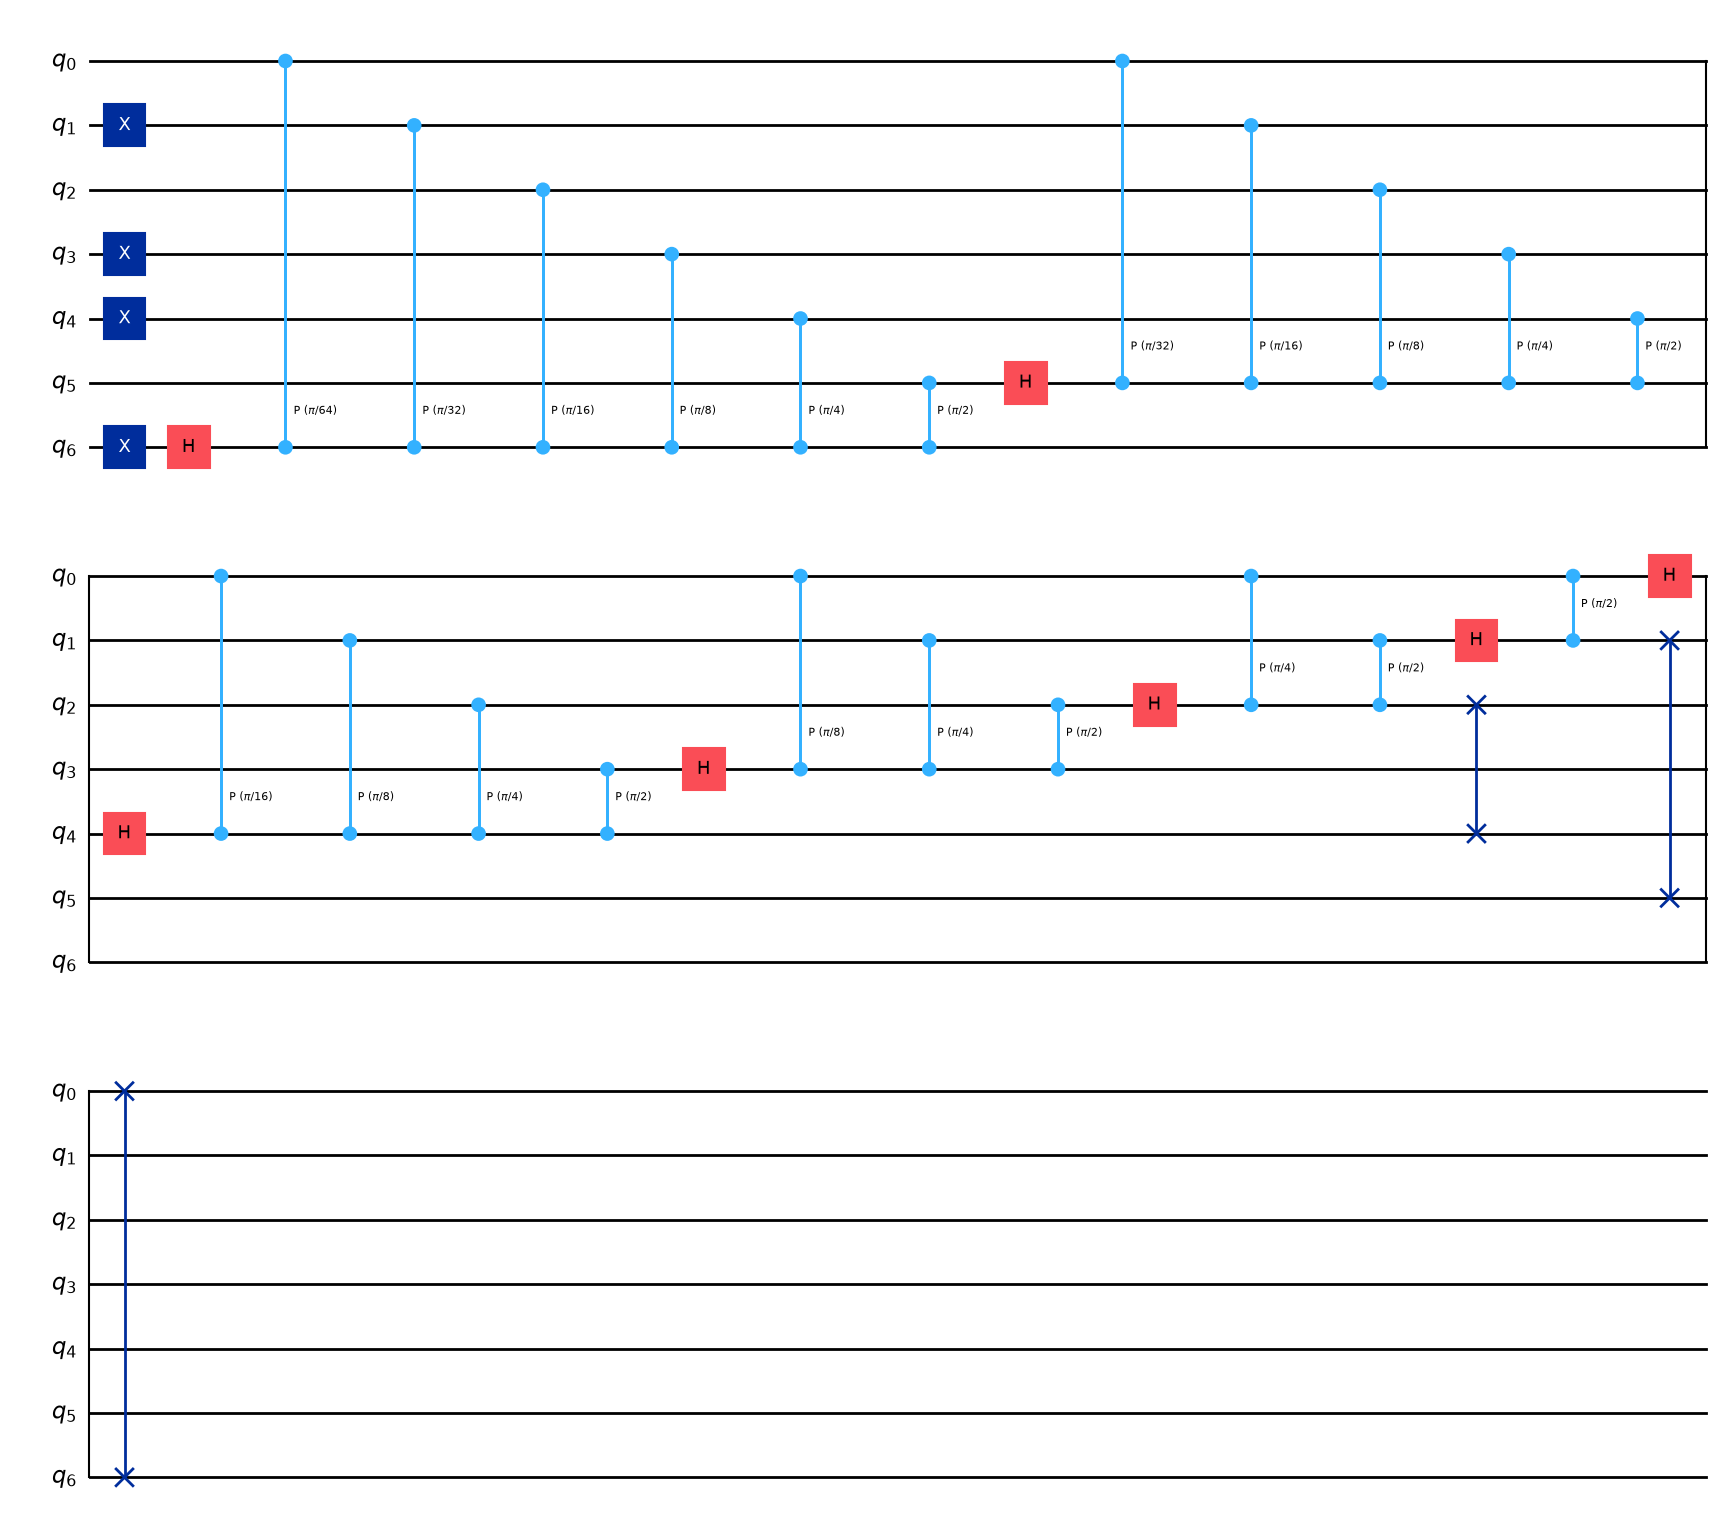

In [10]:
qft(qc, 7)
# qc.measure_all()
qc.draw(output='mpl')

In [11]:
sim = AerSimulator()
qc_state = qc.copy()
qc_state.save_statevector()
statevector = sim.run(transpile(qc_state, sim)).result().get_statevector()

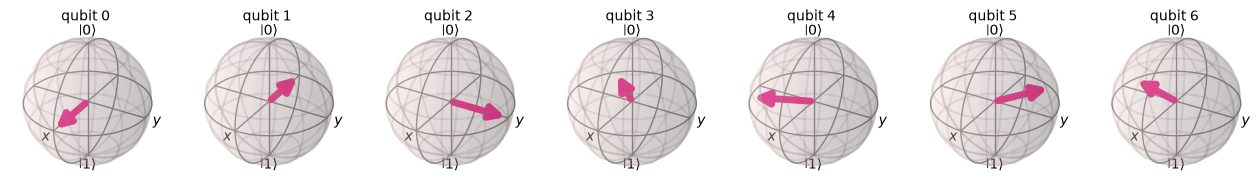

In [12]:
plot_bloch_multivector(statevector)

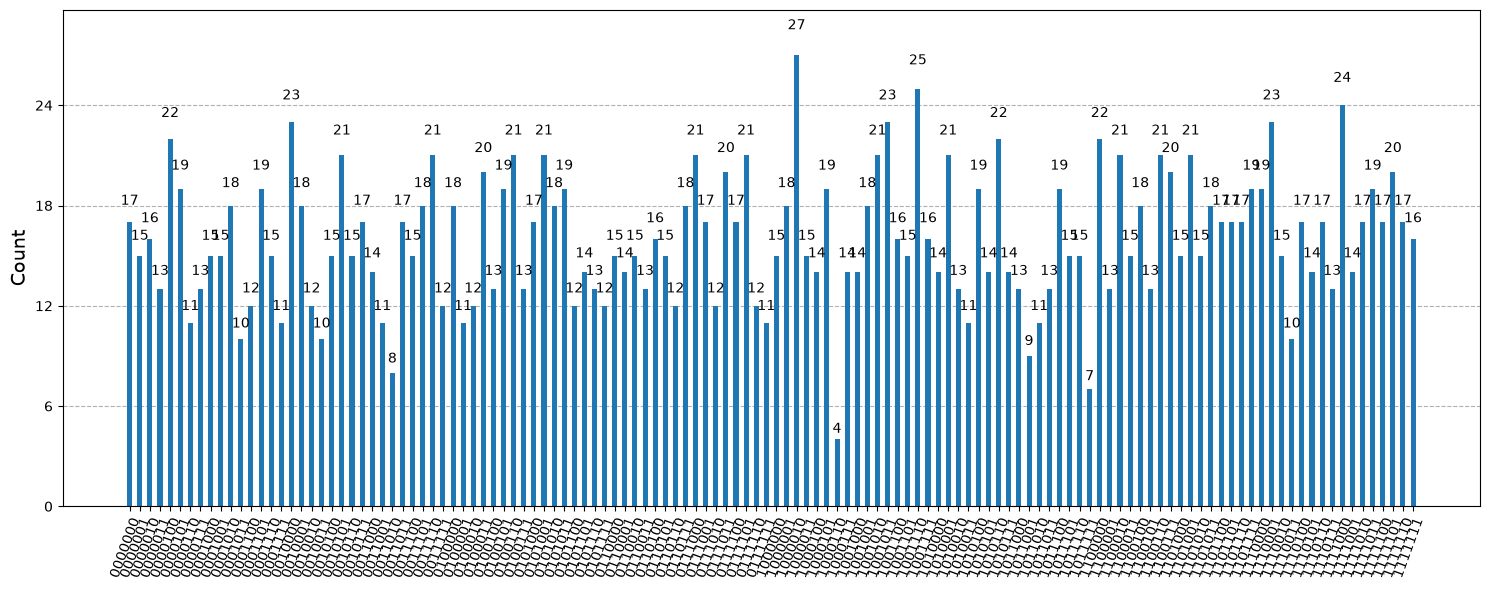

In [13]:
qc_qft_measure = qc.copy()
qc_qft_measure.measure_all()
job = sim.run(transpile(qc_qft_measure, sim), shots=2048)
result = job.result().get_counts()
plot_histogram(result, figsize=(15, 6))

In [14]:
inverse_qft = qft(QuantumCircuit(n), n).inverse()
qc.compose(inverse_qft, inplace=True)

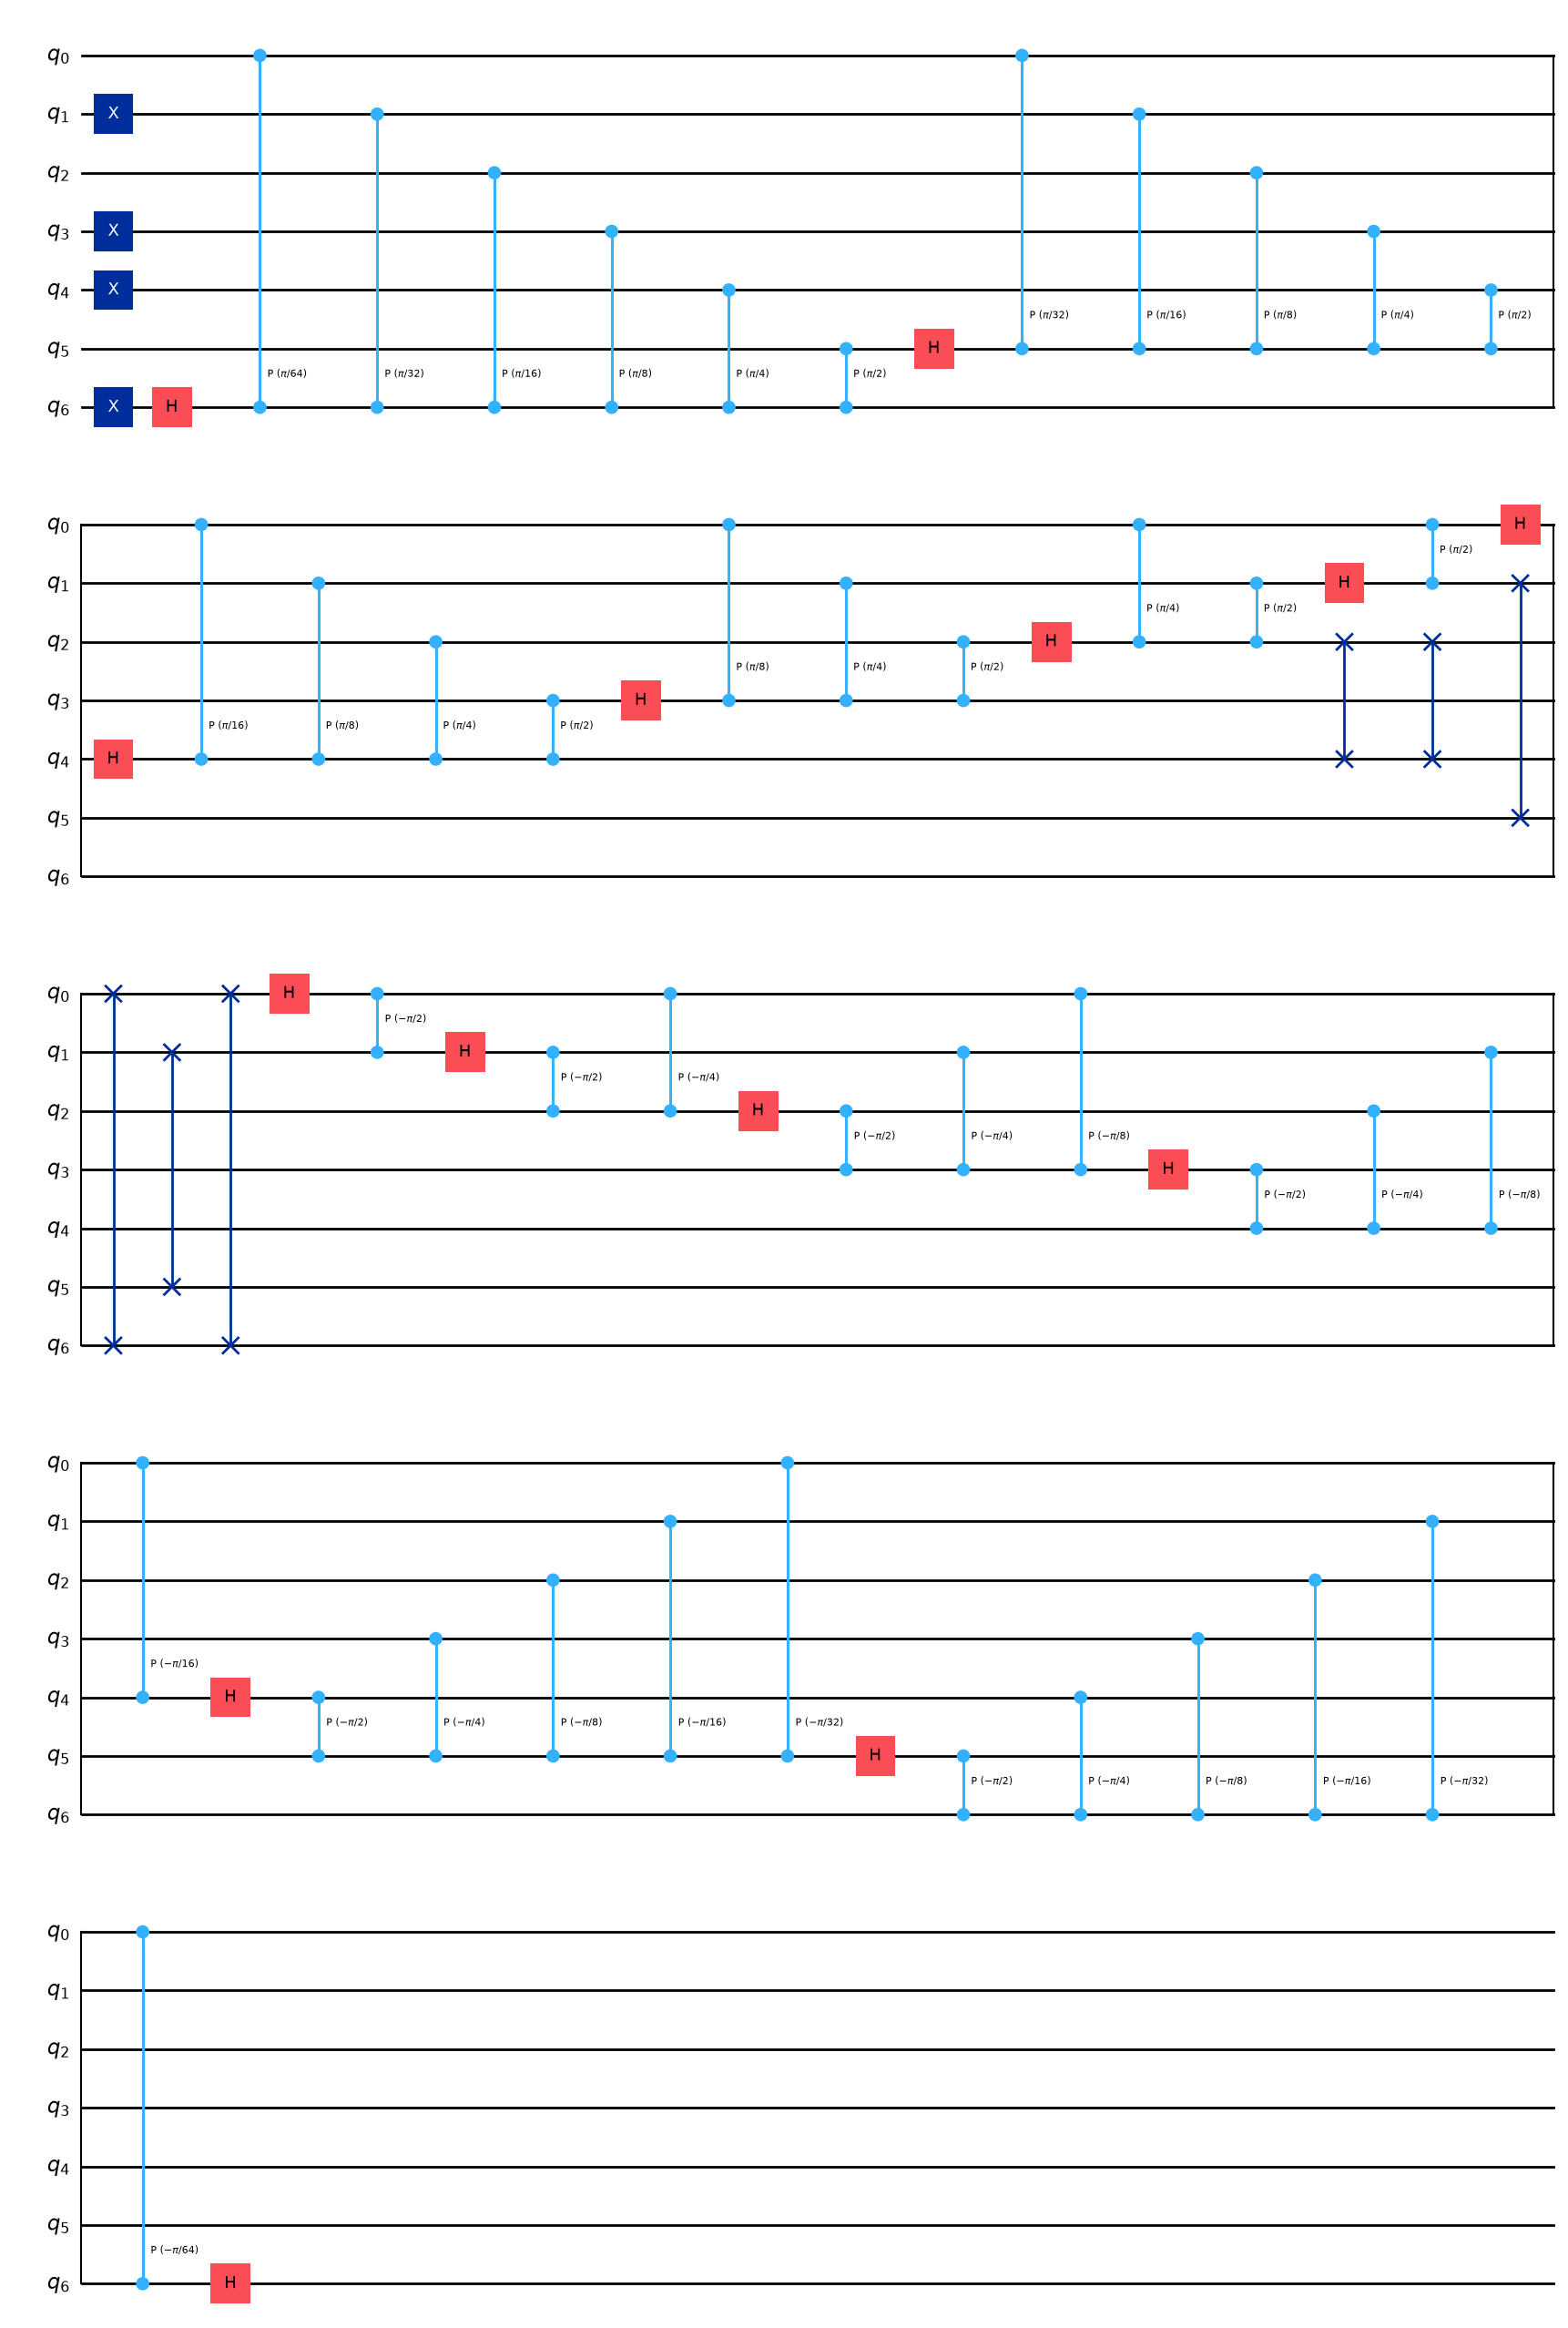

In [15]:
qc.decompose()
qc.draw(output='mpl')

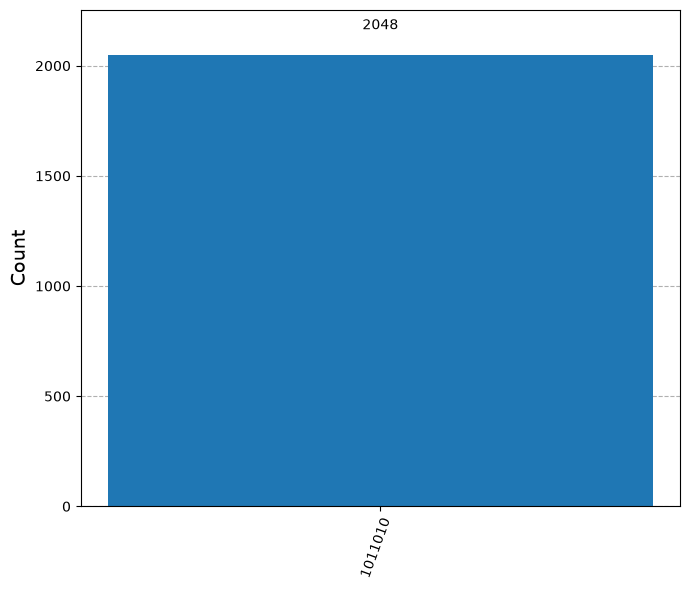

In [17]:
qc_final = qc.copy()
qc_final.measure_all()
job1 = sim.run(transpile(qc_final, sim), shots=2048)
result1 = job1.result().get_counts()
plot_histogram(result1, figsize=(7, 6))